[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Mecanismos y tratamiento de valores faltantes.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete · Módulo I: *Datos y su calidad*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En este *notebook* se distinguirán los mecanismos de faltantes (MCAR, MAR y MNAR), se perfilarán los faltantes de un *dataset* y se compararán estrategias de tratamiento y su efecto en las distribuciones.

## 🧭 Cómo usar este *notebook*.

* Ejecuta las celdas **en orden** (`Shift + Enter`).
* 🟢 **Ejercicio básico:** lo que todos deben dominar.
* 🔴 **Reto (opcional):** para quien termina antes o quiere profundizar. Si no da tiempo en clase, se puede resolver como práctica.
* Las celdas `# TU CÓDIGO AQUÍ` y *✍️ Tu respuesta* son para ti.

## 📚 Referencia de la API: curso py311.

Los métodos de limpieza (`isna`, `notna`, `fillna`, `interpolate`, `dropna`, `duplicated`, `drop_duplicates`, …) se explican uno por uno en [py311 · 20 Limpieza y datos faltantes](https://github.com/PythonistaMX/py311/blob/main/20_limpieza_y_datos_faltantes.ipynb), y el accesor `.str` en [py311 · 23 El accesor `str` de *pandas*](https://github.com/PythonistaMX/py311/blob/main/23_el_accesor_str_de_pandas.ipynb). Aquí se usan sin repasarlos a detalle: la sesión se dedica a **decidir** qué hacer con cada problema de calidad y a medir las consecuencias.

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3. Allá las columnas de texto aparecen como `object` y se usa `inplace=True`; aquí el texto es `str` y se **reasigna** (`df["col"] = df["col"].fillna(...)`) o se usa `df.loc[...] = ...`, como se explicó en la sección 1.1 de `03_pandas_3_esencial.ipynb`.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)

* La siguiente celda leerá `penguins` y `titanic` y mostrará su forma.

In [2]:
pinguinos = pd.read_csv(os.path.join(DATA, "penguins.csv"))
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
pinguinos.shape, titanic.shape

((344, 7), (891, 15))

---
## 1. Mecanismos de faltantes y cómo perfilarlos (15 min).

| Mecanismo | La probabilidad de faltar depende de… | Ejemplo | Consecuencia |
|---|---|---|---|
| **MCAR** (*Missing Completely At Random*) | nada: azar puro | Se cae una hoja del cuaderno de campo | Eliminar filas solo reduce *n*; no sesga |
| **MAR** (*Missing At Random*) | **otras variables observadas** | Falta la edad más en tercera clase | Sesga si se ignora; se corrige condicionando (imputar por grupo) |
| **MNAR** (*Missing Not At Random*) | **el propio valor faltante** | Los de ingreso alto no reportan su ingreso | Sesga, y los datos solos no pueden demostrarlo ni corregirlo |

**Advertencia:** no existe una prueba que confirme MCAR o MAR con certeza. Con los datos solo se puede **descartar** MCAR (si la falta depende de algo observado); MNAR se argumenta con conocimiento del dominio.

### Simulación: el mismo *dataset* con tres mecanismos.

Se tomarán las masas completas de `penguins`, se les quitará cerca de un tercio de los valores con cada mecanismo y se comparará la media observada con la verdadera.

**¿Por qué simular?** En datos reales nunca se conoce el valor que falta, así que no se puede medir el sesgo de una decisión. En una simulación sí: se parte de datos completos, se borran valores con una regla conocida y se compara lo observado con la verdad. Es la misma estrategia que se usará en las sesiones 5 y 6 para evaluar métodos.

* La siguiente celda simulará los tres mecanismos y guardará las columnas `masa_MCAR`, `masa_MAR` y `masa_MNAR`.

In [3]:
completos = pinguinos.dropna(subset=["body_mass_g"]).reset_index(drop=True)
masa_real = completos["body_mass_g"]

probabilidades = {
    "MCAR": np.full(len(completos), 0.30),
    "MAR": np.where(completos["species"] == "Gentoo", 0.60, 0.15),
    "MNAR": 0.6 / (1 + np.exp(-(masa_real - 4500) / 300)),
}
sim = completos[["species", "body_mass_g"]].copy()
for nombre, p in probabilidades.items():
    sim[f"masa_{nombre}"] = masa_real.mask(rng.random(len(sim)) < p)
masa_real.mean().round(1)

np.float64(4201.8)

* La siguiente celda comparará el porcentaje de faltantes, la media observada y el sesgo de cada mecanismo.

In [4]:
resumen_sim = pd.DataFrame({
    "% faltante": sim.filter(like="masa_").isna().mean() * 100,
    "media observada": sim.filter(like="masa_").mean(),
}).round(1)
resumen_sim["sesgo vs. real"] = (resumen_sim["media observada"] - masa_real.mean()).round(1)
resumen_sim

,% faltante,media observada,sesgo vs. real
masa_MCAR,33.0,4182.4,-19.4
masa_MAR,25.1,4033.0,-168.8
masa_MNAR,21.6,3977.5,-224.3


**Interpretación:** con MCAR, aunque falta un tercio, la media observada solo se desvía unos 19 g (puro azar). Con MAR (faltan más los Gentoo) se desvía −169 g, y con MNAR (faltan más los pesados) −224 g. **Más faltantes no implica más sesgo:** MCAR tiene el mayor porcentaje y el menor sesgo. Lo que importa es **de qué depende** la falta.

* La siguiente celda perfilará por especie la proporción de faltantes de cada mecanismo.

In [5]:
sim.filter(like="masa_").isna().groupby(sim["species"]).mean().round(2)

,masa_MCAR,masa_MAR,masa_MNAR
species,,,
Adelie,0.36,0.09,0.06
Chinstrap,0.22,0.10,0.04
Gentoo,0.36,0.53,0.50


**Interpretación:** con MCAR, la proporción de faltantes es parecida en todas las especies (0.22 a 0.36, variación aleatoria); con MAR y MNAR, los Gentoo pierden la mitad de sus datos y las otras especies menos de 10%. Perfilar por grupo es la forma práctica de **descartar MCAR**. MAR y MNAR se ven iguales aquí: los datos no permiten distinguirlos, solo el conocimiento del dominio.

* **MCAR:** la media casi no cambia y la proporción de faltantes es pareja entre especies.
* **MAR:** la falta es mucho mayor en Gentoo (se ve en el perfil) y la media observada **subestima** porque se pierden los más pesados. Como la causa (especie) está observada, se puede corregir condicionando en ella.
* **MNAR:** también subestima, pero el perfil por especie **no** revela la causa completa: depende del valor que no se ve.

### Perfilar faltantes: conteos, patrones y mapa.

Los conteos por columna ya los da `perfil_rapido` (ejercicio 1 de `07_duplicados_e_inconsistencias.ipynb`). Para decidir, interesa además **qué columnas faltan juntas** y **dónde** se concentran los faltantes.

* La siguiente celda mostrará los **patrones**: qué combinaciones de columnas faltan juntas.

In [6]:
pinguinos.isna().value_counts().rename("n_filas")

species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  sex  
False    False   False           False          False              False        False    333
                                                                                True       9
                 True            True           True               True         True       2
Name: n_filas, dtype: int64

**Interpretación:** en el `penguins` original hay solo tres patrones: 333 filas completas, 9 filas a las que solo les falta `sex` y 2 filas sin ninguna medida. Las 2 filas vacías son candidatas claras a eliminarse; las 9 sin sexo conservan medidas útiles.

* La siguiente celda dibujará un mapa de faltantes, en el que cada línea oscura es un `NaN`.

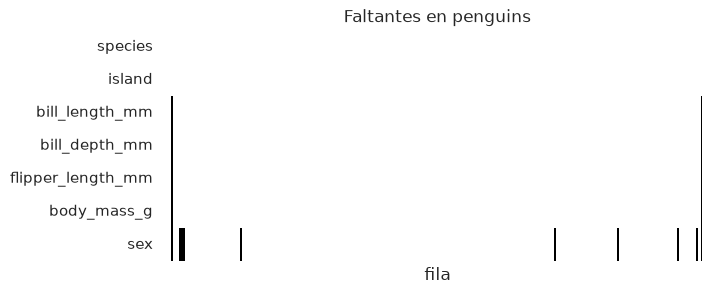

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(pinguinos.isna().T, cbar=False, cmap="Greys", ax=ax)
ax.set(xlabel="fila", title="Faltantes en penguins")
ax.set_xticks([])
plt.show()

### 🟢 Ejercicio 1 · ¿MCAR, MAR o MNAR?

**🎯 Objetivo:** clasificar mecanismos de faltantes en situaciones reales. **Qué se espera aprender:** a razonar de qué depende la falta, que es lo que decide el tratamiento.

Clasifica cada caso y justifica en una frase:
1. En una encuesta de salud, las personas con mayor consumo de alcohol tienden a no contestar la pregunta sobre consumo de alcohol.
2. Un lector de código de barras falla al azar en 2% de las lecturas.
3. En `tips`, el mesero olvidó anotar la propina más a menudo en las cenas de fin de semana (cuando hay más trabajo), y `day` y `time` sí están registrados.
4. En `penguins`, a 2 pingüinos les faltan **todas** las medidas.

**✅ Respuesta sugerida:**

1. **MNAR:** la falta depende del propio valor (consumo alto ⇒ no responde).
2. **MCAR:** la falla no depende de ninguna variable.
3. **MAR:** depende de `day` y `time`, que están observadas; se puede corregir condicionando en ellas.
4. Lo más probable es que sean individuos **no medidos** (se registró su presencia pero no se tomaron las medidas). Con 2 filas sin ninguna medida no hay forma razonable de imputar: se **eliminan** y se documenta. Por sí solos no permiten distinguir el mecanismo, pero son 2 de 344 y el impacto es mínimo.

**💡 Ideas clave de la sección 1:**
* MCAR, MAR y MNAR se distinguen por **de qué depende** la falta, no por cuánto falta.
* Perfilar la falta por grupos permite descartar MCAR; MNAR solo se argumenta con conocimiento del dominio.

---
## 2. Tratamiento de faltantes y su efecto (30 min).

| Estrategia | Cuándo | Costo |
|---|---|---|
| **Eliminar filas** (`dropna`) | Pocos faltantes y MCAR | Pierde *n*; sesga si no es MCAR |
| **Eliminar columna** | La columna casi no tiene datos o no es relevante | Pierde la variable |
| **Imputar media o mediana global** | Rápido, pocos faltantes | **Reduce la varianza**, crea un pico artificial, distorsiona relaciones |
| **Imputar por grupo** (`groupby().transform`) | MAR con la causa observada | Mejor, pero sigue subestimando la variabilidad dentro del grupo |
| **Indicador de faltante** | Siempre que se impute: conserva la información de *que faltaba* | Una columna más |
| Imputación múltiple o con modelos | Análisis inferencial serio | Más complejo; fuera del alcance de hoy |

Se usará el escenario **MAR** de la simulación, donde se conoce la verdad.

**Concepto: por qué imputar con un valor único reduce la varianza.** Si se sustituyen $m$ faltantes por $\bar{x}$, esos valores aportan $(\bar{x} - \bar{x})^2 = 0$ a la suma de cuadrados, pero sí cuentan en el denominador:

$$s^2_{\text{imputada}} = \frac{\sum_{\text{observados}} (x_i - \bar{x})^2}{n + m - 1} < s^2_{\text{observada}}$$

La distribución gana un pico artificial en $\bar{x}$ y parece menos variable de lo que es.

* La siguiente celda aplicará las cuatro estrategias y creará el indicador `faltaba`.

In [8]:
mar = sim[["species", "body_mass_g", "masa_MAR"]].assign(
    elim=lambda d: d["masa_MAR"],
    imp_media=lambda d: d["masa_MAR"].fillna(d["masa_MAR"].mean()),
    imp_mediana=lambda d: d["masa_MAR"].fillna(d["masa_MAR"].median()),
    imp_grupo=lambda d: d["masa_MAR"].fillna(d.groupby("species")["masa_MAR"].transform("median")),
    faltaba=lambda d: d["masa_MAR"].isna(),
)
mar.head()

,species,body_mass_g,masa_MAR,elim,imp_media,imp_mediana,imp_grupo,faltaba
0,Adelie,3750.0,3750.0,3750.0,3750.000000,3750.0,3750.0,False
1,Adelie,3800.0,NaN,NaN,4033.007812,3800.0,3650.0,True
2,Adelie,3250.0,NaN,NaN,4033.007812,3800.0,3650.0,True
3,Adelie,3450.0,3450.0,3450.0,3450.000000,3450.0,3450.0,False
4,Adelie,3650.0,3650.0,3650.0,3650.000000,3650.0,3650.0,False


* La siguiente celda comparará conteo, media, mediana y desviación estándar de cada estrategia contra la verdad.

In [9]:
tabla = mar[["body_mass_g", "elim", "imp_media", "imp_mediana", "imp_grupo"]].agg(["count", "mean", "median", "std"]).T.round(1)
tabla.index = ["real (sin faltantes)", "eliminar", "media global", "mediana global", "mediana por especie"]
tabla

,count,mean,median,std
real (sin faltantes),342.0,4201.8,4050.0,802.0
eliminar,256.0,4033.0,3800.0,755.1
media global,342.0,4033.0,4033.0,653.0
mediana global,342.0,3974.4,3800.0,660.8
mediana por especie,342.0,4213.3,4000.0,786.8


**Interpretación:** en el escenario MAR, eliminar y la media global dan la misma media sesgada (4,033 g contra 4,202 g reales); la media global además baja la desviación estándar de 802 a 653 g. La mediana **por especie** queda a 12 g de la media real y conserva casi toda la dispersión (787 g), porque la falta dependía de la especie y se imputó **condicionando** en ella.

* La siguiente celda graficará el efecto de tres estrategias sobre la distribución.

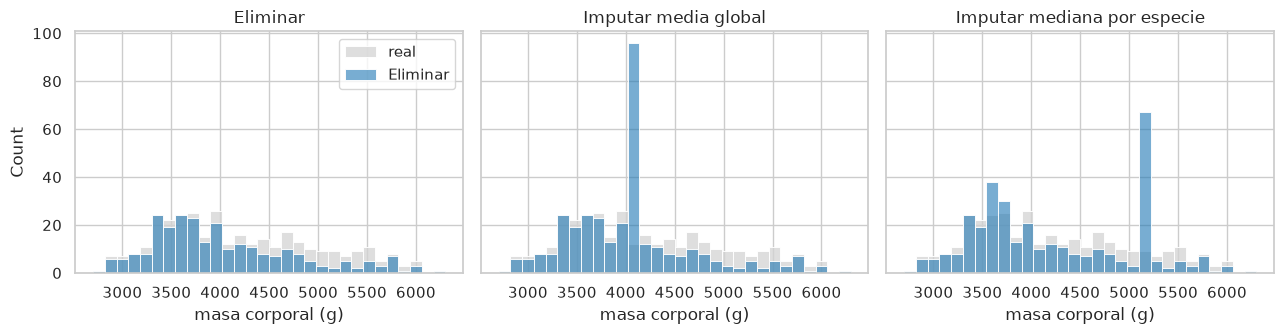

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True)
for ax, columna, titulo in zip(axes, ["elim", "imp_media", "imp_grupo"],
                               ["Eliminar", "Imputar media global", "Imputar mediana por especie"]):
    sns.histplot(mar["body_mass_g"], bins=30, color="lightgray", label="real", ax=ax)
    sns.histplot(mar[columna].dropna(), bins=30, color="tab:blue", alpha=0.6, label=titulo, ax=ax)
    ax.set(title=titulo, xlabel="masa corporal (g)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Lecturas clave:**
* **Eliminar** con MAR sesga la media hacia abajo, porque se perdieron Gentoo pesados.
* **Media o mediana global** crea un **pico artificial** y **encoge la desviación estándar**: subestima la variabilidad y hará que, más adelante, los intervalos de confianza sean falsamente estrechos.
* **Por grupo** recupera mejor la media y la forma, porque condiciona en la variable que explica la falta.
* Conviene guardar siempre el **indicador** (`faltaba`) para revisar después si los imputados se comportan distinto.

### 2.1 Decidir el tratamiento: preguntas y consecuencias.

Antes de escribir `dropna` o `fillna` conviene responder, por escrito:

| Pregunta | Si la respuesta es… | Decisión razonable | Consecuencia que hay que reportar |
|---|---|---|---|
| ¿Cuántos faltan? | Muy pocos (≈ 1 a 2%) | Eliminar o imputar da casi igual | Cuántas filas se perdieron |
| ¿De qué depende la falta? | De una variable observada (MAR) | Imputar **por grupo** o analizar por estratos | Que la imputación supone MAR |
| | Del propio valor (MNAR) | No hay corrección con los datos; análisis de sensibilidad | Que el resultado puede estar sesgado y en qué dirección |
| ¿Para qué se usará la variable? | Para describir su distribución | Evitar imputar con un valor único | La varianza y la forma cambian |
| | Para relacionarla con otras | Evitar la imputación global | Las correlaciones se atenúan |
| ¿Se eliminan filas completas? | `dropna()` sin `subset` | Casi nunca: usar `subset` con las columnas del análisis | La muestra puede dejar de representar a la población |

Las dos celdas siguientes muestran las dos consecuencias menos evidentes.

**Consecuencia 1: imputar con la media global debilita las relaciones.** Los valores imputados son todos iguales, sin importar la aleta del pingüino, así que la correlación aleta–masa baja.

* La siguiente celda comparará la correlación aleta–masa con los datos reales y con dos imputaciones del escenario MAR.

In [11]:
aleta = completos["flipper_length_mm"]
{"real": round(float(aleta.corr(mar["body_mass_g"])), 3),
 "imputación con media global": round(float(aleta.corr(mar["imp_media"])), 3),
 "imputación con mediana por especie": round(float(aleta.corr(mar["imp_grupo"])), 3)}

{'real': 0.871,
 'imputación con media global': 0.674,
 'imputación con mediana por especie': 0.876}

**Interpretación:** la imputación global baja la correlación de 0.871 a 0.674: los valores imputados no siguen la relación con la aleta. La imputación por especie la conserva (0.876). Si después se analizarán relaciones, la imputación global es una mala decisión aunque la media "se vea bien".

Con la media global la correlación baja de 0.87 a cerca de 0.67: un análisis posterior concluiría que la relación es más débil de lo que es. Con la mediana por especie casi no cambia, porque la especie explica tanto la falta como buena parte de la aleta y de la masa.

**Consecuencia 2: `dropna()` sin `subset` cambia la población.** En `titanic`, `deck` falta en 77% de las filas. Eliminar toda fila con algún faltante deja una muestra dominada por primera clase, porque las cubiertas se registraban sobre todo para esos pasajeros.

* La siguiente celda comparará el tamaño, la composición por clase y la supervivencia de `titanic` completo y después de `dropna()`.

In [12]:
sin_faltantes = titanic.dropna()
pd.DataFrame({
    "completo": titanic["class"].value_counts(normalize=True),
    "tras dropna()": sin_faltantes["class"].value_counts(normalize=True),
}).round(3), len(titanic), len(sin_faltantes), round(float(titanic["survived"].mean()), 3), round(float(sin_faltantes["survived"].mean()), 3)

(        completo  tras dropna()
 class                          
 First      0.242          0.863
 Second     0.207          0.082
 Third      0.551          0.055,
 891,
 182,
 0.384,
 0.676)

**Interpretación:** `dropna()` sin `subset` conserva solo 182 de 891 pasajeros (los que tienen `deck`, casi todos de primera clase): la primera clase pasa de 24% a 86% y la tasa de supervivencia de 38% a 68%. La muestra deja de representar al barco. **Siempre** se usa `subset` con las columnas del análisis.

De 891 pasajeros quedan 182; la primera clase pasa de 24% a 86% de la muestra y la tasa de supervivencia, de 38% a 68%. Cualquier conclusión sobre esa muestra describe a otra población. Por eso se usa `dropna(subset=[...])` solo con las columnas que necesita cada análisis.

**💡 Ideas clave de la sección 2:**
* Eliminar filas sesga si la falta no es MCAR; `dropna()` siempre con `subset`.
* Imputar con un valor único reduce la varianza y atenúa las correlaciones; imputar por grupo corrige MAR si la causa está observada.
* Se agrega un indicador de "faltaba" y se reporta el efecto de la decisión.

---
## ✅ Cierre.

**Práctica (sin calificación, en Classroom):** terminar los ejercicios 🟢 pendientes de este *notebook* y, si es posible, un reto 🔴.

**Siguiente *notebook*:** `09_auditoria_de_calidad.ipynb`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>